In [29]:
# Set up

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from pathlib import Path
FIGURE_DIR = Path('../../results/figures/eda/eda_02_match_data')
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load Group 2 files
games        = pd.read_csv('../../data/raw/games.csv')
game_events  = pd.read_csv('../../data/raw/game_events.csv')
game_lineups = pd.read_csv('../../data/raw/game_lineups.csv', low_memory=False)
club_games   = pd.read_csv('../../data/raw/club_games.csv')

print(" Group 2 — Match Data loaded!")
print(f"  games        : {games.shape}")
print(f"  game_events  : {game_events.shape}")
print(f"  game_lineups : {game_lineups.shape}")
print(f"  club_games   : {club_games.shape}")

 Group 2 — Match Data loaded!
  games        : (88665, 23)
  game_events  : (1269845, 11)
  game_lineups : (3166515, 10)
  club_games   : (177330, 11)


In [30]:
# Overviews of all 4 files

group2 = {
    'games'        : games,
    'game_events'  : game_events,
    'game_lineups' : game_lineups,
    'club_games'   : club_games
}

print(f"{'File':<25} {'Rows':>10} {'Cols':>6} {'Missing':>10} {'Missingxd%':>10} {'Memory':>10}")
print("-" * 75)

for name, df in group2.items():
    rows        = df.shape[0]
    cols        = df.shape[1]
    missing     = df.isnull().sum().sum()
    missing_pct = round(missing / (rows * cols) * 100, 2)
    memory      = df.memory_usage().sum() / 1024**2
    print(f"{name:<25} {rows:>10,} {cols:>6} {missing:>10,} "
          f"{missing_pct:>9.2f}% {memory:>9.1f}MB")

File                            Rows   Cols    Missing Missingxd%     Memory
---------------------------------------------------------------------------
games                         88,665     23     80,421      3.94%      15.6MB
game_events                1,269,845     11  1,817,429     13.01%     106.6MB
game_lineups               3,166,515     10          3      0.00%     241.6MB
club_games                   177,330     11    104,612      5.36%      14.9MB


In [31]:
print("=" * 60)
print("UNIQUE DATA CHECK — games.csv")
print("=" * 60)
print(f"Shape  : {games.shape}")
print(f"Purpose: Match info (score, date, stadium, attendance)\n")

for col in games.columns:
    n_unique   = games[col].nunique()
    null_count = games[col].isnull().sum()
    dtype      = games[col].dtype

    if n_unique <= 15:
        values = games[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = games[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — games.csv
Shape  : (88665, 23)
Purpose: Match info (score, date, stadium, attendance)

game_id
  dtype=int64 | unique=88,665 | null=0
  Top 5: {986822: 1, 1026846: 1, 1026847: 1, 1027001: 1, 1027002: 1}

competition_id
  dtype=object | unique=67 | null=0
  Top 5: {'IT1': 5310, 'ES1': 5310, 'GB1': 5308, 'FR1': 4996, 'TR1': 4618}

season
  dtype=int64 | unique=18 | null=0
  Top 5: {2024: 10036, 2025: 9305, 2022: 6008, 2023: 5951, 2021: 5939}

round
  dtype=object | unique=124 | null=0
  Top 5: {'First Round': 3355, 'Second Round': 2597, '2. Matchday': 1957, '1. Matchday': 1956, '3. Matchday': 1946}

date
  dtype=object | unique=4,411 | null=0
  Top 5: {'2025-09-27': 132, '2025-08-31': 118, '2025-11-09': 116, '2025-11-01': 115, '2025-10-25': 115}

home_club_id
  dtype=int64 | unique=2,976 | null=0
  Top 5: {418: 402, 131: 395, 631: 383, 506: 382, 281: 379}

away_club_id
  dtype=int64 | unique=2,630 | null=0
  Top 5: {418: 406, 131: 404, 13: 394, 368: 389, 281: 384}

ho

In [32]:
print("=" * 60)
print("UNIQUE DATA CHECK — game_events.csv")
print("=" * 60)
print(f"Shape  : {game_events.shape}")
print(f"Purpose: Every event in every match (goals, cards, subs)\n")

for col in game_events.columns:
    n_unique   = game_events[col].nunique()
    null_count = game_events[col].isnull().sum()
    dtype      = game_events[col].dtype

    if n_unique <= 15:
        values = game_events[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = game_events[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — game_events.csv
Shape  : (1269845, 11)
Purpose: Every event in every match (goals, cards, subs)

game_event_id
  dtype=object | unique=1,269,845 | null=0
  Top 5: {'8c8b99b892a2f73f88c0bd698805d607': 1, '60d28dc455d299f5abdb65d7204fef40': 1, '71280d139049475e02eb7627897da117': 1, 'dbb0d095a58423d8377d6b5b6b9f258f': 1, '6948606e52c10f6a2032ebe64355fe14': 1}

date
  dtype=object | unique=4,409 | null=0
  Top 5: {'2025-08-31': 1917, '2025-11-01': 1904, '2025-09-27': 1883, '2025-11-09': 1865, '2025-10-25': 1829}

game_id
  dtype=int64 | unique=88,521 | null=0
  Top 5: {4420807: 48, 4420886: 47, 3292973: 45, 4623595: 45, 3459017: 44}

minute
  dtype=int64 | unique=121 | null=0
  Top 5: {90: 92579, 46: 57537, 78: 25275, 80: 25068, 75: 25041}

type
  dtype=object | unique=4 | null=0
  Values: ['Cards', 'Goals', 'Substitutions', 'Shootout']

club_id
  dtype=int64 | unique=3,166 | null=0
  Top 5: {131: 6333, 418: 6279, 368: 5964, 13: 5963, 27: 5641}

club_name
  dtype=object

In [9]:
print("=" * 60)
print("UNIQUE DATA CHECK — game_lineups.csv")
print("=" * 60)
print(f"Shape  : {game_lineups.shape}")
print(f"Purpose: Starting XI + substitutes per match\n")

for col in game_lineups.columns:
    n_unique   = game_lineups[col].nunique()
    null_count = game_lineups[col].isnull().sum()
    dtype      = game_lineups[col].dtype

    if n_unique <= 15:
        values = game_lineups[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = game_lineups[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — game_lineups.csv
Shape  : (3166515, 10)
Purpose: Starting XI + substitutes per match

game_lineups_id
  dtype=object | unique=3,166,515 | null=0
  Top 5: {'27b21947b73cecce0a99129569f607a8': 1, 'b2dbe01c3656b06c8e23e9de714e26bb': 1, 'b50a3ec6d52fd1490aab42042ac4f738': 1, 'e18985880a402888b2bb58ed2b7b2cc4': 1, '1bf6d508f041bc88dd716921b531db16': 1}

date
  dtype=object | unique=3,933 | null=0
  Top 5: {'2025-09-27': 4947, '2025-11-01': 4685, '2025-11-09': 4579, '2025-10-25': 4457, '2025-08-31': 4385}

game_id
  dtype=int64 | unique=80,912 | null=0
  Top 5: {4368739: 60, 4680812: 56, 4625339: 55, 4680811: 54, 4368874: 53}

player_id
  dtype=int64 | unique=114,715 | null=0
  Top 5: {125781: 661, 44058: 645, 38253: 634, 74229: 631, 241641: 629}

club_id
  dtype=int64 | unique=3,123 | null=0
  Top 5: {418: 14454, 506: 14447, 46: 14435, 131: 14359, 12: 14195}

player_name
  dtype=object | unique=110,829 | null=0
  Top 5: {'Danilo': 1374, 'Paulinho': 1331, 'João Pedro': 11

In [10]:
print("=" * 60)
print("UNIQUE DATA CHECK — club_games.csv")
print("=" * 60)
print(f"Shape  : {club_games.shape}")
print(f"Purpose: Club-level stats per match (win/loss/draw)\n")

for col in club_games.columns:
    n_unique   = club_games[col].nunique()
    null_count = club_games[col].isnull().sum()
    dtype      = club_games[col].dtype

    if n_unique <= 15:
        values = club_games[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = club_games[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — club_games.csv
Shape  : (177330, 11)
Purpose: Club-level stats per match (win/loss/draw)

game_id
  dtype=int64 | unique=88,665 | null=0
  Top 5: {986822: 2, 1026846: 2, 1026847: 2, 1027001: 2, 1027002: 2}

club_id
  dtype=int64 | unique=3,270 | null=0
  Top 5: {418: 808, 131: 799, 13: 768, 281: 763, 631: 758}

own_goals
  dtype=int64 | unique=18 | null=0
  Top 5: {1: 56999, 0: 48305, 2: 38574, 3: 19219, 4: 8210}

own_position
  dtype=float64 | unique=21 | null=50618
  Top 5: {1.0: 7593, 2.0: 7590, 5.0: 7589, 3.0: 7589, 4.0: 7588}

own_manager_name
  dtype=object | unique=7,015 | null=1688
  Top 5: {'Diego Simeone': 767, 'Pep Guardiola': 720, 'Unai Emery': 718, 'José Mourinho': 640, 'Brendan Rodgers': 628}

opponent_id
  dtype=int64 | unique=3,270 | null=0
  Top 5: {418: 808, 131: 799, 13: 768, 281: 763, 631: 758}

opponent_goals
  dtype=int64 | unique=18 | null=0
  Top 5: {1: 56999, 0: 48305, 2: 38574, 3: 19219, 4: 8210}

opponent_position
  dtype=float64 | unique=

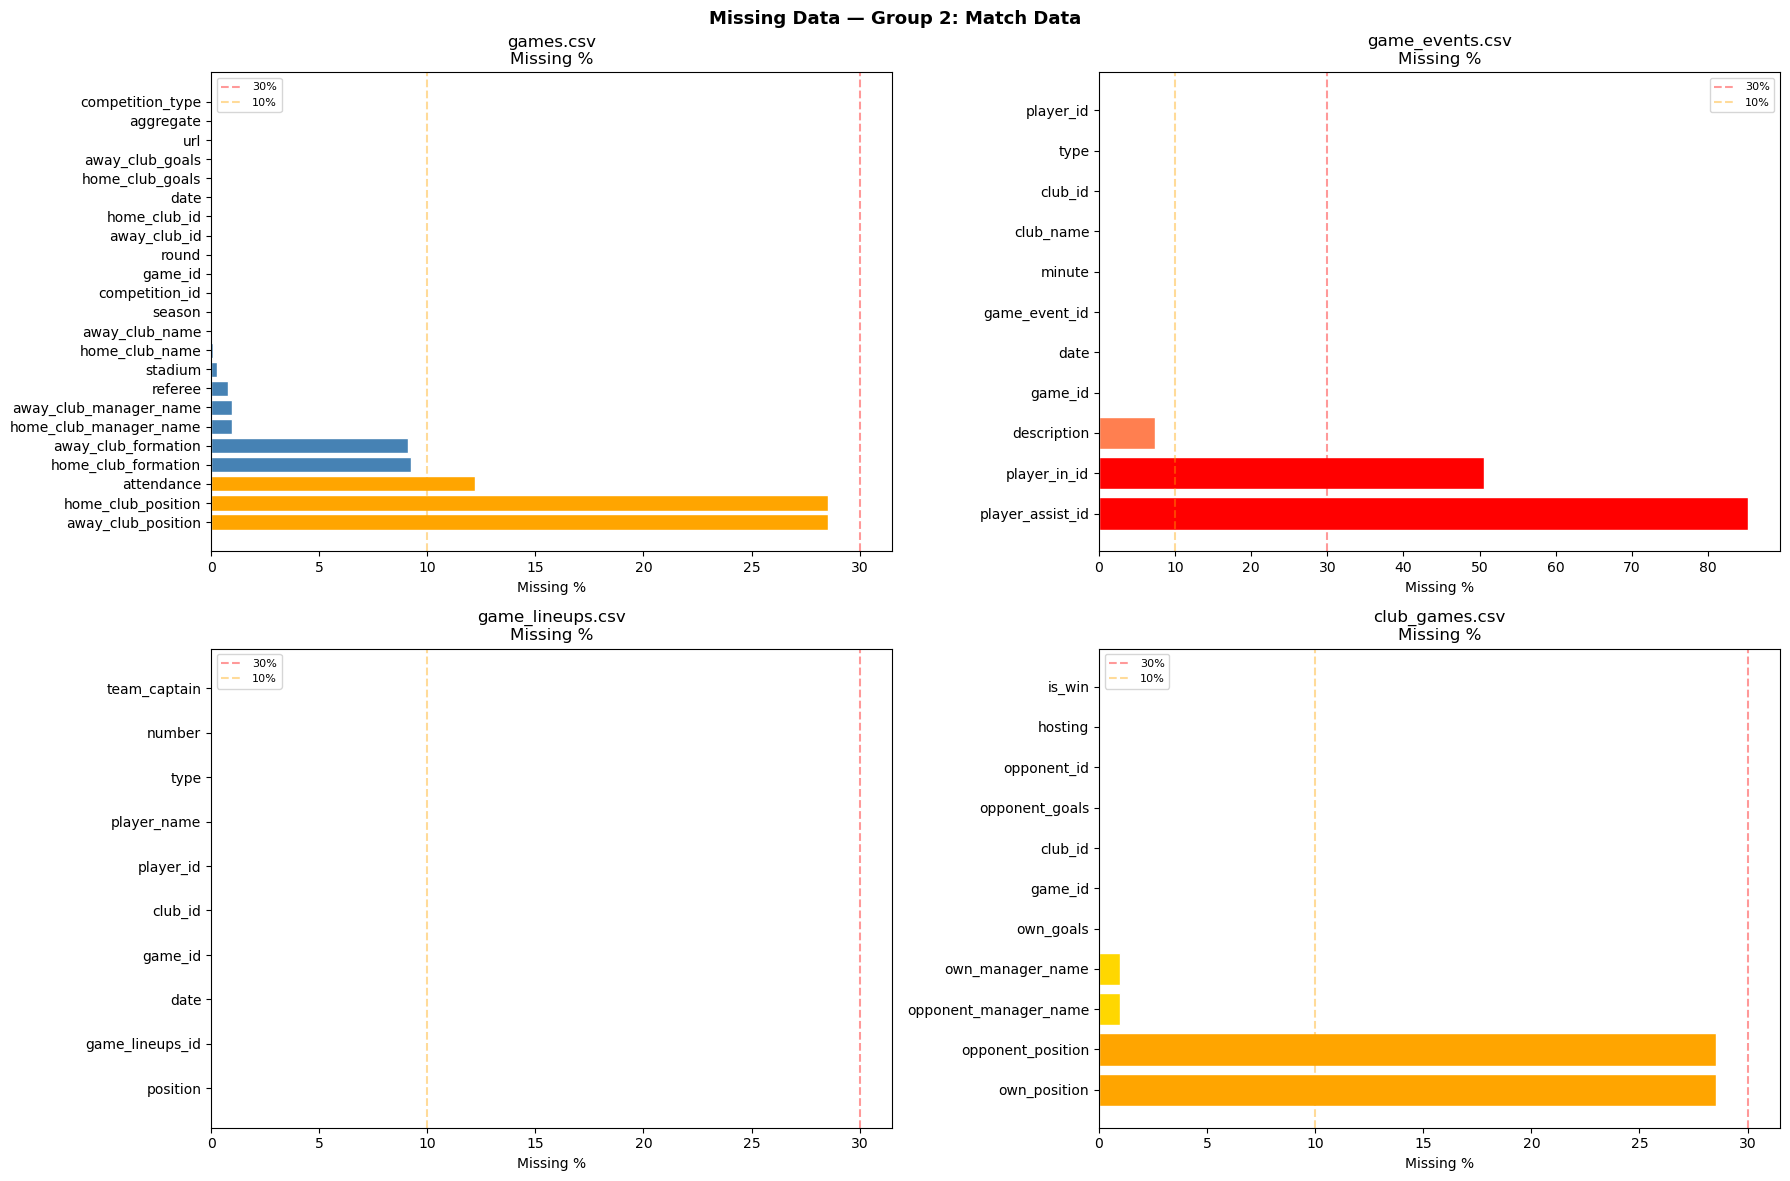

Saved


In [11]:
#  Missing Visualization: All 4 files

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

files_info = [
    (games,        'games.csv',        'steelblue'),
    (game_events,  'game_events.csv',  'coral'),
    (game_lineups, 'game_lineups.csv', 'mediumseagreen'),
    (club_games,   'club_games.csv',   'gold')
]

for ax, (df_f, name, color) in zip(axes.flatten(), files_info):
    pct = (df_f.isnull().sum() / len(df_f) * 100).sort_values(ascending=False)
    bar_colors = ['red' if p > 30 else 'orange' if p > 10 else color
                  for p in pct.values]
    ax.barh(pct.index, pct.values, color=bar_colors, edgecolor='white')
    ax.set_title(f'{name}\nMissing %')
    ax.set_xlabel('Missing %')
    ax.axvline(30, color='red',    linestyle='--', alpha=0.4, label='30%')
    ax.axvline(10, color='orange', linestyle='--', alpha=0.4, label='10%')
    ax.legend(fontsize=8)

plt.suptitle('Missing Data — Group 2: Match Data',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_group2_missing_data_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

In [12]:
# games.csv:Basic Info

print("=" * 60)
print("FILE 1: games.csv")
print("=" * 60)
print(f"Purpose : Match information (score, date, stadium, attendance)")
print(f"Shape   : {games.shape}")
print(f"\nColumns: {games.columns.tolist()}")
print(f"\nFirst 3 rows:")
games.head(3)

FILE 1: games.csv
Purpose : Match information (score, date, stadium, attendance)
Shape   : (88665, 23)

Columns: ['game_id', 'competition_id', 'season', 'round', 'date', 'home_club_id', 'away_club_id', 'home_club_goals', 'away_club_goals', 'home_club_position', 'away_club_position', 'home_club_manager_name', 'away_club_manager_name', 'stadium', 'attendance', 'referee', 'url', 'home_club_formation', 'away_club_formation', 'home_club_name', 'away_club_name', 'aggregate', 'competition_type']

First 3 rows:


,game_id,competition_id,season,round,date,home_club_id,away_club_id,home_club_goals,away_club_goals,home_club_position,...,stadium,attendance,referee,url,home_club_formation,away_club_formation,home_club_name,away_club_name,aggregate,competition_type
0,1026846,FIWC,2009,Round of 16,2010-06-26,3449,3589,2,1,NaN,...,Nelson Mandela Bay Stadium,30597.0,Wolfgang Stark,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,Uruguay,South Korea,2:1,national_team_competition
1,1026847,FIWC,2009,Round of 16,2010-06-27,3437,6303,3,1,NaN,...,FNB-Stadium,84377.0,Roberto Rosetti,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,Argentina,Mexico,3:1,national_team_competition
2,1027001,FIWC,2009,Round of 16,2010-06-26,3505,3441,1,2,NaN,...,Royal Bafokeng Stadium,34976.0,Viktor Kassai,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,United States,Ghana,1:2,national_team_competition


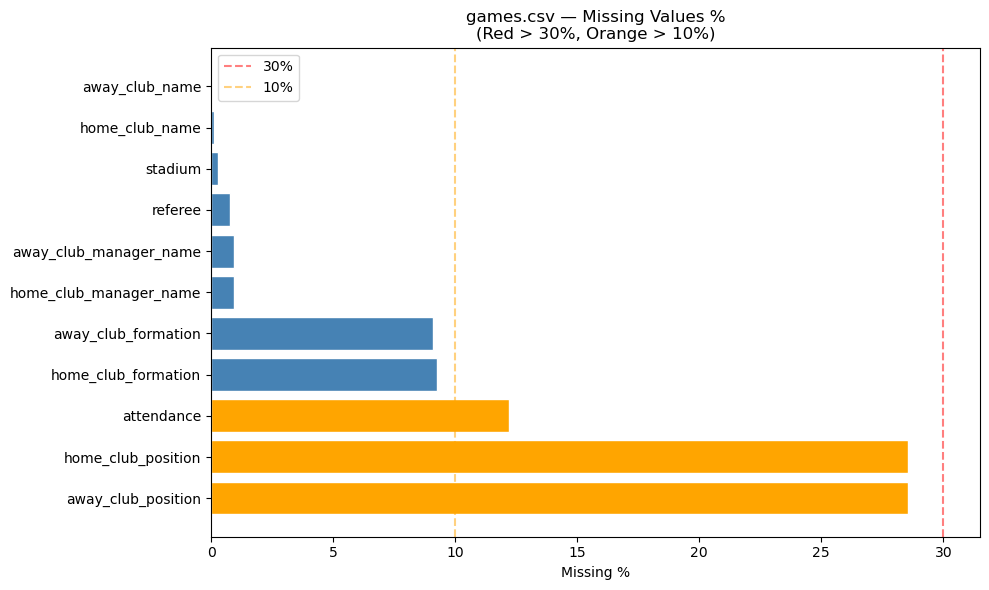


Missing Values Detail:
                        count  percent
away_club_position      25309    28.54
home_club_position      25309    28.54
attendance              10812    12.19
home_club_formation      8194     9.24
away_club_formation      8068     9.10
home_club_manager_name    844     0.95
away_club_manager_name    844     0.95
referee                   677     0.76
stadium                   242     0.27
home_club_name             86     0.10
away_club_name             36     0.04


In [13]:
# games.csv: Univariate Missing

# Missing values
missing_games = pd.DataFrame({
    'count'  : games.isnull().sum(),
    'percent': (games.isnull().sum() / len(games) * 100).round(2)
}).sort_values('percent', ascending=False)

missing_only = missing_games[missing_games['count'] > 0]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['coral' if p > 30 else 'orange' if p > 10 else 'steelblue'
          for p in missing_only['percent']]
ax.barh(missing_only.index, missing_only['percent'],
        color=colors, edgecolor='white')
ax.set_title('games.csv — Missing Values %\n(Red > 30%, Orange > 10%)')
ax.set_xlabel('Missing %')
ax.axvline(30, color='red', linestyle='--', alpha=0.5, label='30%')
ax.axvline(10, color='orange', linestyle='--', alpha=0.5, label='10%')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '02_games_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nMissing Values Detail:")
print(missing_only.to_string())

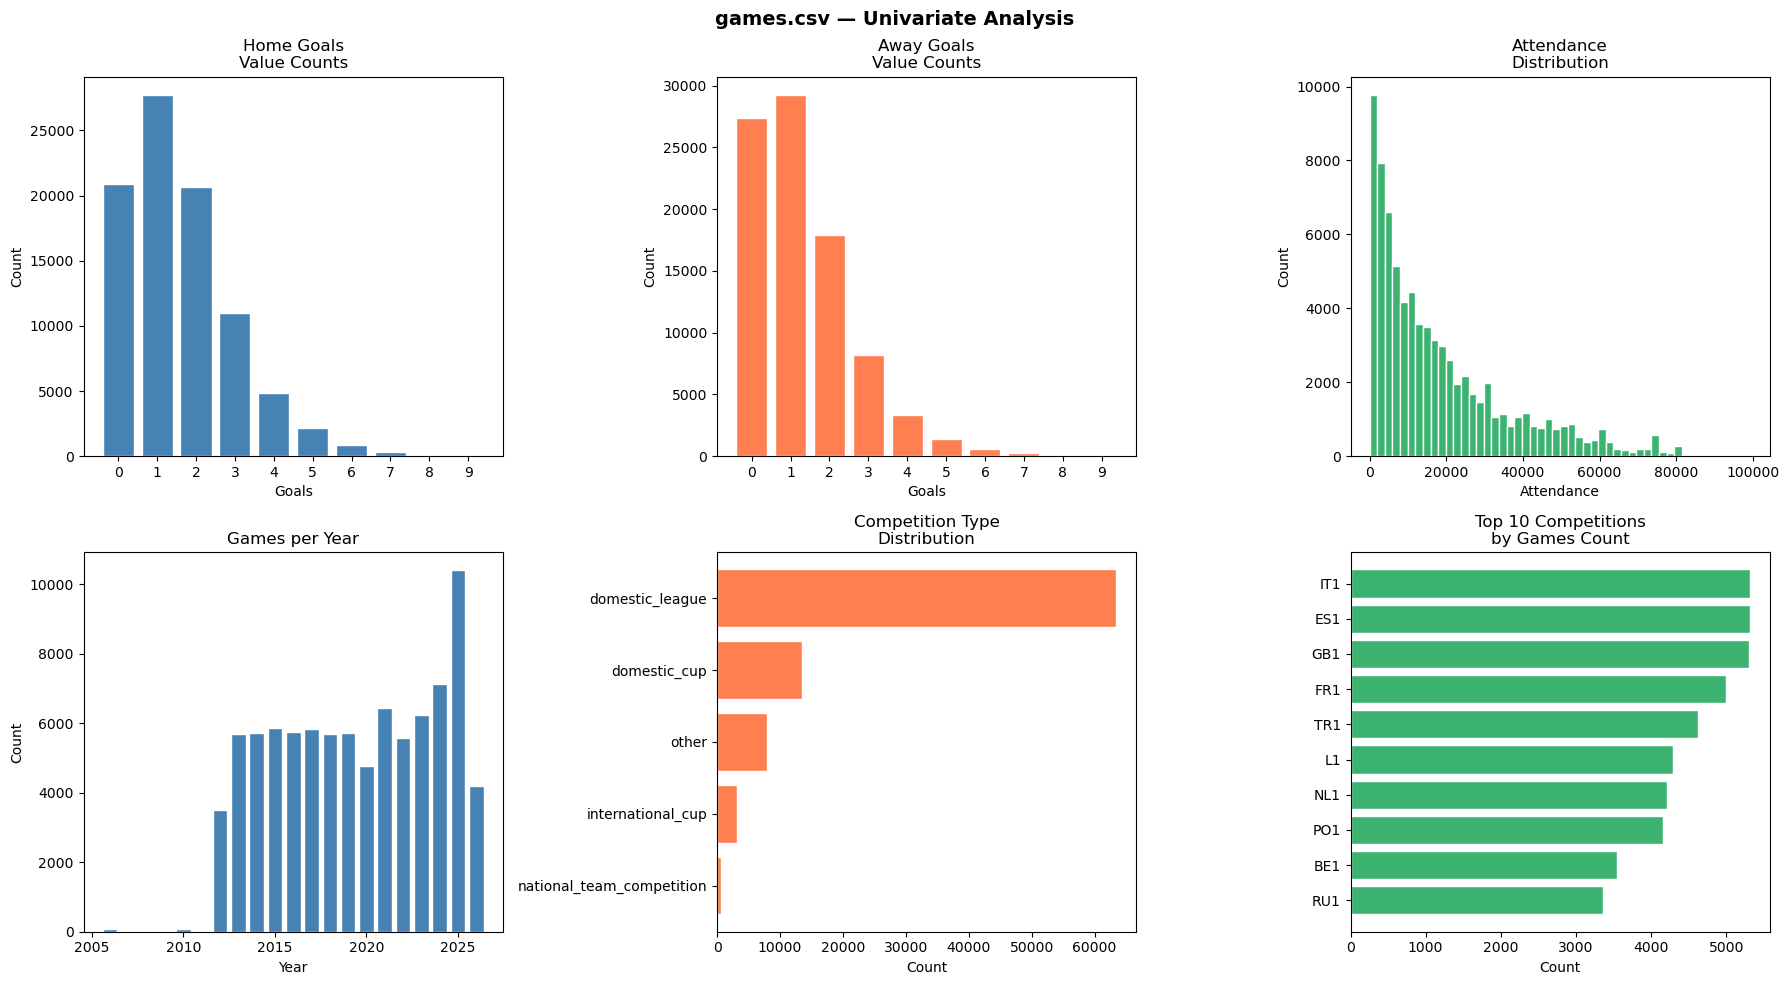

Saved


In [14]:
games['date'] = pd.to_datetime(games['date'])

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Goals home
val = games['home_club_goals'].value_counts().sort_index().head(10)
axes[0, 0].bar(val.index.astype(str), val.values,
               color='steelblue', edgecolor='white')
axes[0, 0].set_title('Home Goals\nValue Counts')
axes[0, 0].set_xlabel('Goals')
axes[0, 0].set_ylabel('Count')

# Goals away
val = games['away_club_goals'].value_counts().sort_index().head(10)
axes[0, 1].bar(val.index.astype(str), val.values,
               color='coral', edgecolor='white')
axes[0, 1].set_title('Away Goals\nValue Counts')
axes[0, 1].set_xlabel('Goals')
axes[0, 1].set_ylabel('Count')

# Attendance distribution
axes[0, 2].hist(games['attendance'].dropna(), bins=50,
                color='mediumseagreen', edgecolor='white')
axes[0, 2].set_title('Attendance\nDistribution')
axes[0, 2].set_xlabel('Attendance')
axes[0, 2].set_ylabel('Count')

# Games per season
games_per_year = games.groupby(games['date'].dt.year).size()
axes[1, 0].bar(games_per_year.index, games_per_year.values,
               color='steelblue', edgecolor='white')
axes[1, 0].set_title('Games per Year')
axes[1, 0].set_xlabel('Year')
axes[1, 0].set_ylabel('Count')
axes[1, 0].tick_params(axis='x', rotation=0)

# Competition type distribution
comp_counts = games['competition_type'].value_counts()
axes[1, 1].barh(comp_counts.index, comp_counts.values,
                color='coral', edgecolor='white')
axes[1, 1].set_title('Competition Type\nDistribution')
axes[1, 1].set_xlabel('Count')
axes[1, 1].invert_yaxis()

# Top 10 competitions
top_comp = games['competition_id'].value_counts().head(10)
axes[1, 2].barh(top_comp.index, top_comp.values,
                color='mediumseagreen', edgecolor='white')
axes[1, 2].set_title('Top 10 Competitions\nby Games Count')
axes[1, 2].set_xlabel('Count')
axes[1, 2].invert_yaxis()

plt.suptitle('games.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_games_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

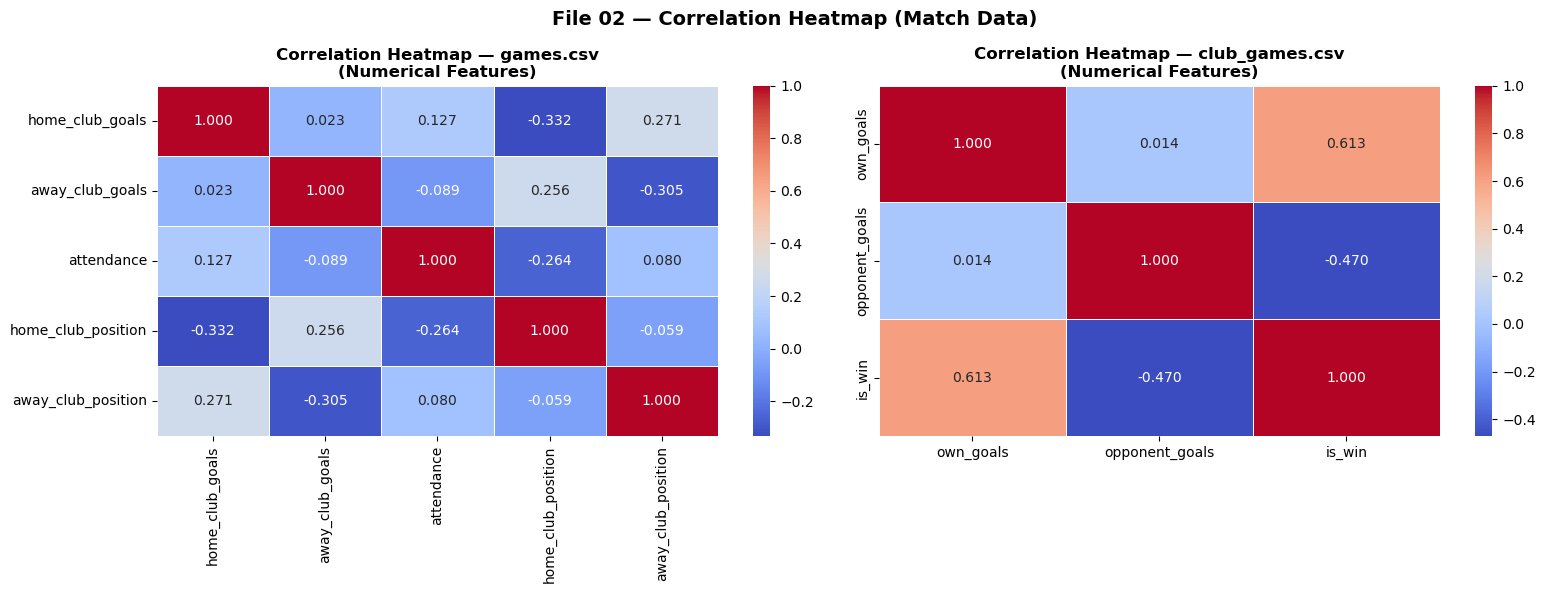

✅ Saved


In [15]:
# Correlation Heatmap — games.csv numerical features
games['date'] = pd.to_datetime(games['date'])

numerical_games = ['home_club_goals', 'away_club_goals', 'attendance',
                   'home_club_position', 'away_club_position']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap — games.csv
corr_games = games[numerical_games].corr()
sns.heatmap(corr_games, annot=True, fmt='.3f',
            cmap='coolwarm', linewidths=0.5,
            ax=axes[0], annot_kws={'size': 10})
axes[0].set_title('Correlation Heatmap — games.csv\n(Numerical Features)',
                  fontsize=12, fontweight='bold')

# Heatmap — club_games.csv
numerical_club = ['own_goals', 'opponent_goals', 'is_win']
corr_club = club_games[numerical_club].corr()
sns.heatmap(corr_club, annot=True, fmt='.3f',
            cmap='coolwarm', linewidths=0.5,
            ax=axes[1], annot_kws={'size': 10})
axes[1].set_title('Correlation Heatmap — club_games.csv\n(Numerical Features)',
                  fontsize=12, fontweight='bold')

plt.suptitle('File 02 — Correlation Heatmap (Match Data)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_match_data_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved")

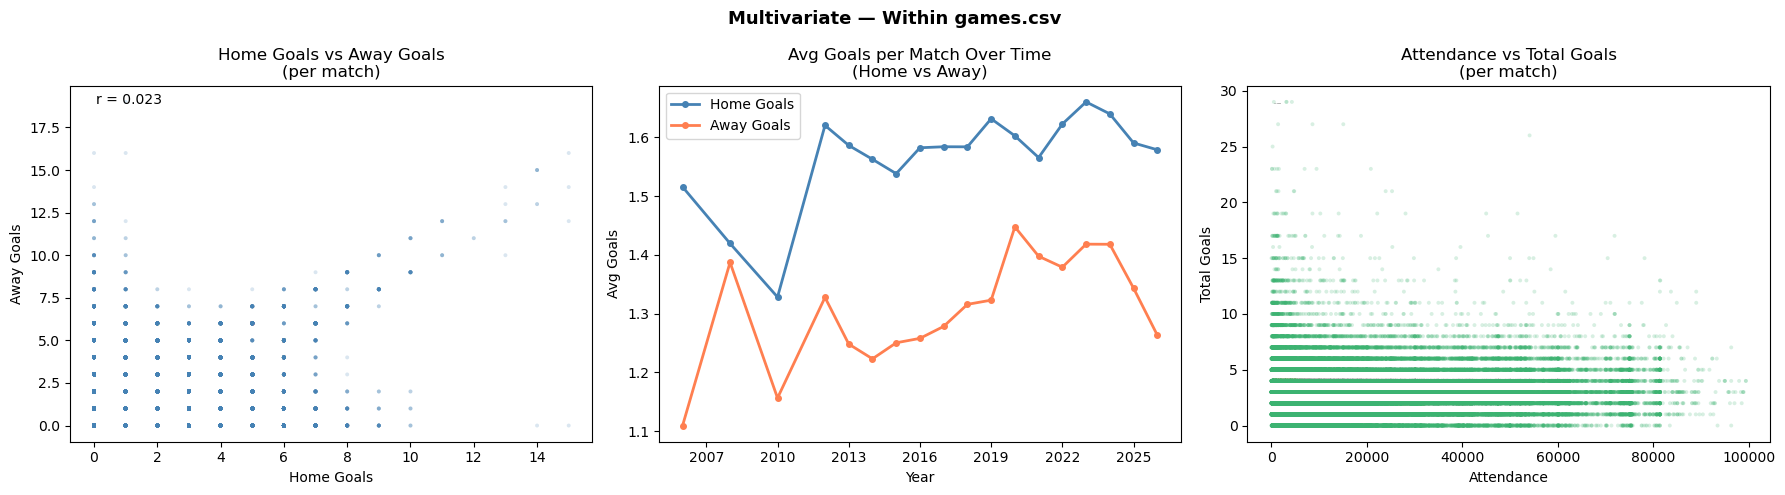

Saved


In [16]:
from matplotlib.ticker import MaxNLocator
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Home vs Away goals scatter
axes[0].scatter(games['home_club_goals'], games['away_club_goals'],
                alpha=0.2, color='steelblue', edgecolors='none', s=8)
axes[0].set_title('Home Goals vs Away Goals\n(per match)')
axes[0].set_xlabel('Home Goals')
axes[0].set_ylabel('Away Goals')
corr = games['home_club_goals'].corr(games['away_club_goals'])
axes[0].text(0.05, 0.95, f'r = {corr:.3f}',
             transform=axes[0].transAxes, fontsize=10)

# Goals trend over time
goals_trend = games.groupby(games['date'].dt.year).agg(
    home_goals = ('home_club_goals', 'mean'),
    away_goals = ('away_club_goals', 'mean')
).reset_index()
axes[1].plot(goals_trend['date'], goals_trend['home_goals'],
             color='steelblue', linewidth=2, marker='o',
             markersize=4, label='Home Goals')
axes[1].plot(goals_trend['date'], goals_trend['away_goals'],
             color='coral', linewidth=2, marker='o',
             markersize=4, label='Away Goals')
axes[1].set_title('Avg Goals per Match Over Time\n(Home vs Away)')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Avg Goals')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=0)
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))

# Attendance vs total goals
games['total_goals'] = games['home_club_goals'] + games['away_club_goals']
axes[2].scatter(games['attendance'], games['total_goals'],
                alpha=0.2, color='mediumseagreen', edgecolors='none', s=8)
axes[2].set_title('Attendance vs Total Goals\n(per match)')
axes[2].set_xlabel('Attendance')
axes[2].set_ylabel('Total Goals')
corr2 = games['attendance'].corr(games['total_goals'])
axes[2].text(0.05, 0.95, f'r = {corr2:.3f}',
             transform=axes[2].transAxes, fontsize=0)

plt.suptitle('Multivariate — Within games.csv',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_games_multivariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

In [17]:
# game_events.csv: Basic Info + Missing

print("=" * 60)
print("FILE 2: game_events.csv")
print("=" * 60)
print(f"Purpose : Every event in every match (goals, cards, subs)")
print(f"Shape   : {game_events.shape}")
print(f"\nColumns: {game_events.columns.tolist()}")

# Missing
missing_events = pd.DataFrame({
    'count'  : game_events.isnull().sum(),
    'percent': (game_events.isnull().sum() / len(game_events) * 100).round(2)
}).sort_values('percent', ascending=False)

print("\nMissing Values:")
print(missing_events[missing_events['count'] > 0].to_string())

FILE 2: game_events.csv
Purpose : Every event in every match (goals, cards, subs)
Shape   : (1269845, 11)

Columns: ['game_event_id', 'date', 'game_id', 'minute', 'type', 'club_id', 'club_name', 'player_id', 'description', 'player_in_id', 'player_assist_id']

Missing Values:
                    count  percent
player_assist_id  1082281    85.23
player_in_id       642003    50.56
description         93145     7.34


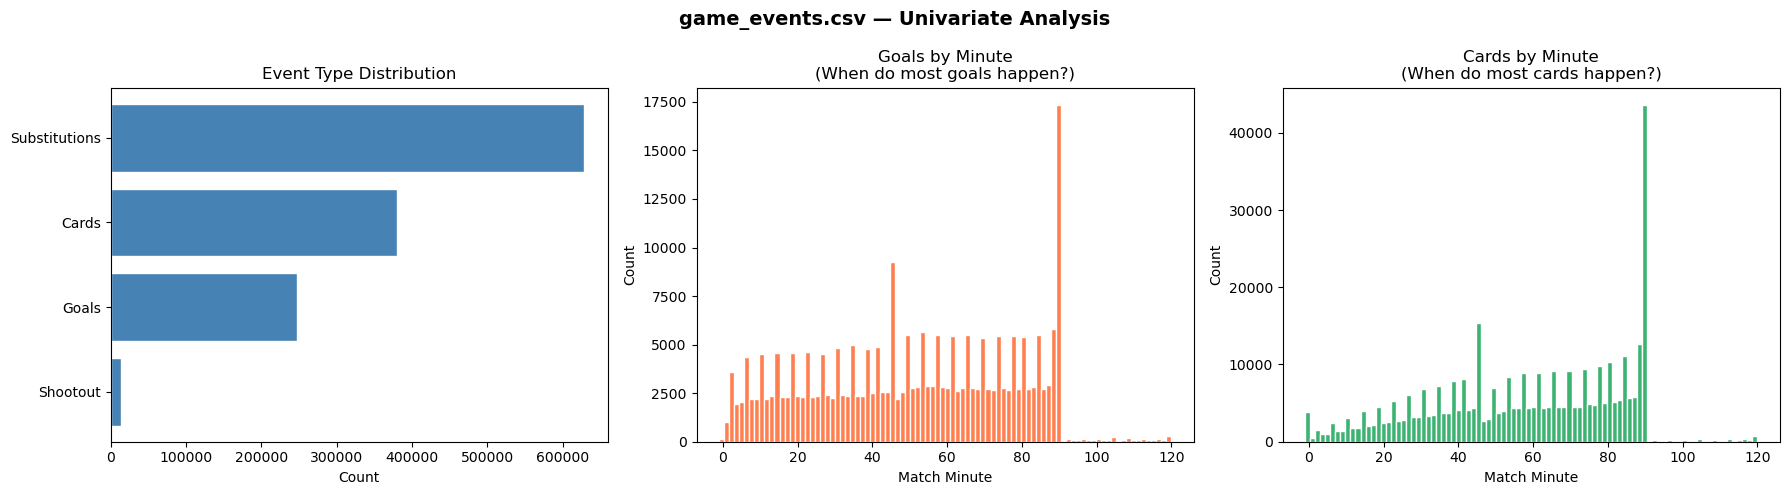

Saved


In [18]:
# Univariate: game_events.csv

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Event type distribution
event_counts = game_events['type'].value_counts()
axes[0].barh(event_counts.index, event_counts.values,
             color='steelblue', edgecolor='white')
axes[0].set_title('Event Type Distribution')
axes[0].set_xlabel('Count')
axes[0].invert_yaxis()

# Goals by minute
goals = game_events[game_events['type'] == 'Goals']
axes[1].hist(goals['minute'].dropna(), bins=90,
             color='coral', edgecolor='white')
axes[1].set_title('Goals by Minute\n(When do most goals happen?)')
axes[1].set_xlabel('Match Minute')
axes[1].set_ylabel('Count')

# Cards by minute
cards = game_events[game_events['type'].isin(['Cards'])]
axes[2].hist(cards['minute'].dropna(), bins=90,
             color='mediumseagreen', edgecolor='white')
axes[2].set_title('Cards by Minute\n(When do most cards happen?)')
axes[2].set_xlabel('Match Minute')
axes[2].set_ylabel('Count')

plt.suptitle('game_events.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '06_game_events_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

In [19]:
# game_lineups.csv: Basic Info

print("=" * 60)
print("FILE 3: game_lineups.csv")
print("=" * 60)
print(f"Purpose : Starting XI + substitutes per match")
print(f"Shape   : {game_lineups.shape}")
print(f"\nColumns: {game_lineups.columns.tolist()}")

# Missing
missing_lineups = pd.DataFrame({
    'count'  : game_lineups.isnull().sum(),
    'percent': (game_lineups.isnull().sum() / len(game_lineups) * 100).round(2)
})
print("\nMissing Values:")
print(missing_lineups[missing_lineups['count'] > 0].to_string())

# Type distribution (starter vs sub)
print("\nLineup Type:")
print(game_lineups['type'].value_counts())

FILE 3: game_lineups.csv
Purpose : Starting XI + substitutes per match
Shape   : (3166515, 10)

Columns: ['game_lineups_id', 'date', 'game_id', 'player_id', 'club_id', 'player_name', 'type', 'position', 'number', 'team_captain']

Missing Values:
          count  percent
position      3      0.0

Lineup Type:
type
starting_lineup    1774467
substitutes        1392048
Name: count, dtype: int64


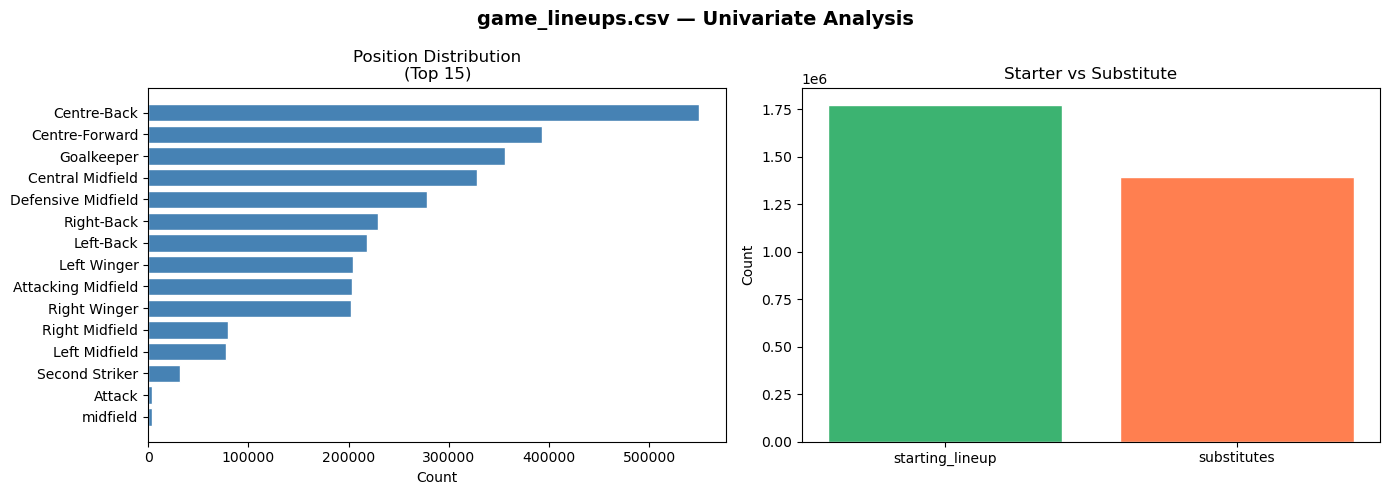

Saved


In [20]:
# game_lineups.csv: Univariate

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Position distribution
pos_counts = game_lineups['position'].value_counts().head(15)
axes[0].barh(pos_counts.index, pos_counts.values,
             color='steelblue', edgecolor='white')
axes[0].set_title('Position Distribution\n(Top 15)')
axes[0].set_xlabel('Count')
axes[0].invert_yaxis()

# Starter vs Substitute
type_counts = game_lineups['type'].value_counts()
axes[1].bar(type_counts.index, type_counts.values,
            color=['mediumseagreen', 'coral'], edgecolor='white')
axes[1].set_title('Starter vs Substitute')
axes[1].set_ylabel('Count')

plt.suptitle('game_lineups.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_game_lineups_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

FILE 4: club_games.csv
Purpose : Club-level stats per match (win/loss/draw)
Shape   : (177330, 11)

Columns: ['game_id', 'club_id', 'own_goals', 'own_position', 'own_manager_name', 'opponent_id', 'opponent_goals', 'opponent_position', 'opponent_manager_name', 'hosting', 'is_win']

Missing Values:
                       count  percent
own_position           50618    28.54
own_manager_name        1688     0.95
opponent_position      50618    28.54
opponent_manager_name   1688     0.95


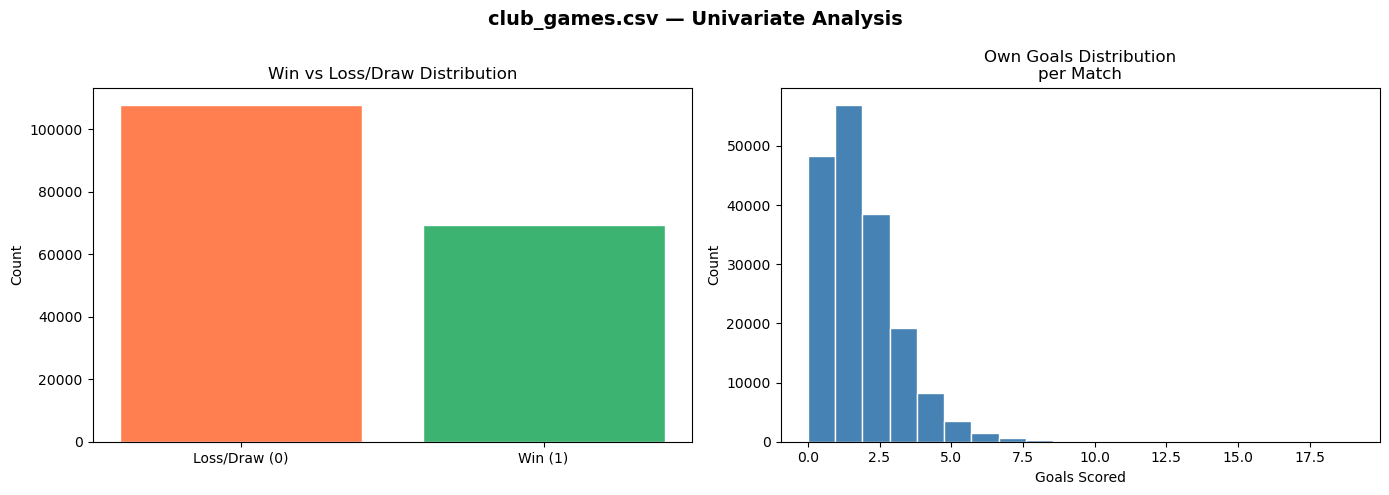

Saved


In [21]:
# club_games.csv: Basic Info + Univariate

print("=" * 60)
print("FILE 4: club_games.csv")
print("=" * 60)
print(f"Purpose : Club-level stats per match (win/loss/draw)")
print(f"Shape   : {club_games.shape}")
print(f"\nColumns: {club_games.columns.tolist()}")

# Missing
missing_club = pd.DataFrame({
    'count'  : club_games.isnull().sum(),
    'percent': (club_games.isnull().sum() / len(club_games) * 100).round(2)
})
print("\nMissing Values:")
print(missing_club[missing_club['count'] > 0].to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Win/Loss distribution
win_counts = club_games['is_win'].value_counts()
axes[0].bar(['Loss/Draw (0)', 'Win (1)'], win_counts.values,
            color=['coral', 'mediumseagreen'], edgecolor='white')
axes[0].set_title('Win vs Loss/Draw Distribution')
axes[0].set_ylabel('Count')

# Goals distribution
axes[1].hist(club_games['own_goals'].dropna(), bins=20,
             color='steelblue', edgecolor='white')
axes[1].set_title('Own Goals Distribution\nper Match')
axes[1].set_xlabel('Goals Scored')
axes[1].set_ylabel('Count')

plt.suptitle('club_games.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '08_club_games_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

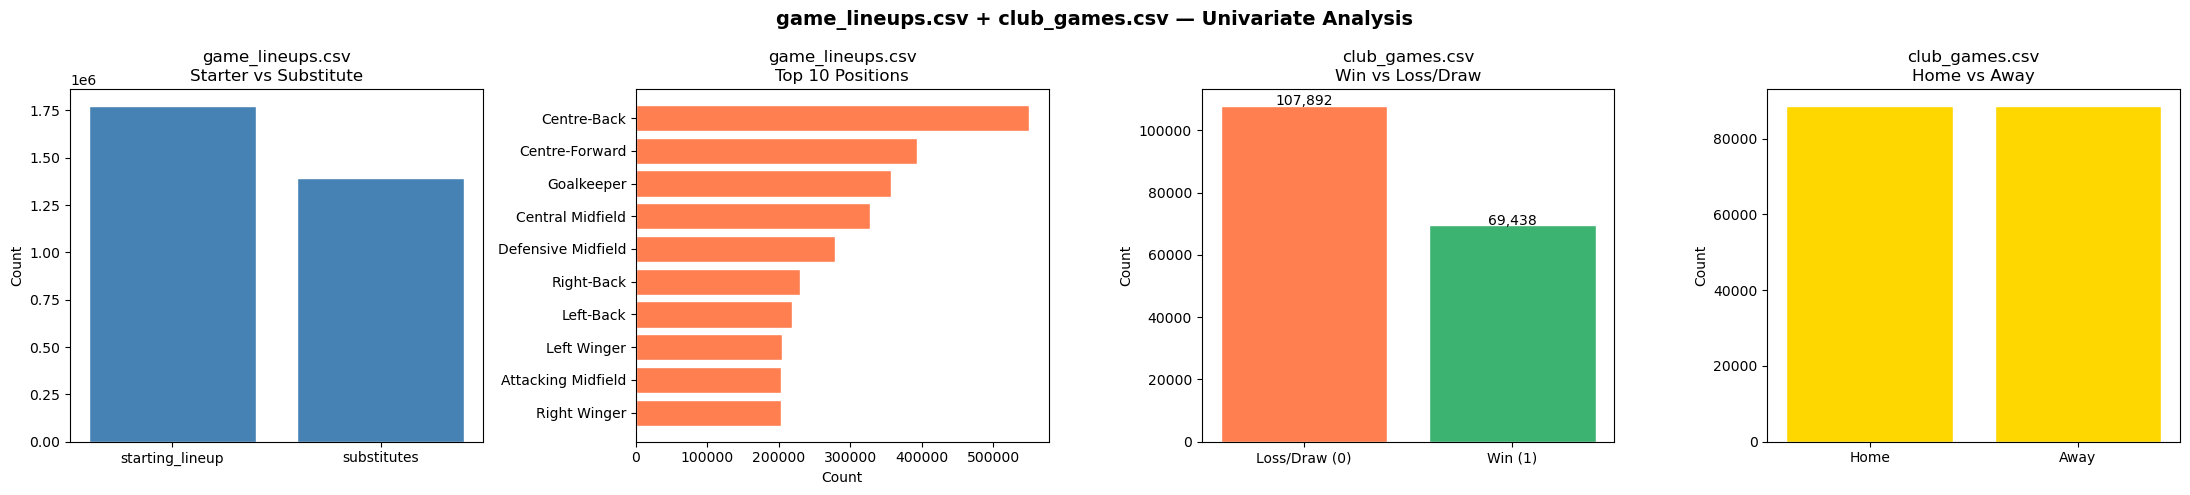

Saved


In [22]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Lineup type
type_counts = game_lineups['type'].value_counts()
axes[0].bar(type_counts.index, type_counts.values,
            color='steelblue', edgecolor='white')
axes[0].set_title('game_lineups.csv\nStarter vs Substitute')
axes[0].set_ylabel('Count')

# Position distribution
pos_counts = game_lineups['position'].value_counts().head(10)
axes[1].barh(pos_counts.index, pos_counts.values,
             color='coral', edgecolor='white')
axes[1].set_title('game_lineups.csv\nTop 10 Positions')
axes[1].set_xlabel('Count')
axes[1].invert_yaxis()

# Win/Loss/Draw
win_counts = club_games['is_win'].value_counts()
axes[2].bar(['Loss/Draw (0)', 'Win (1)'], win_counts.values,
            color=['coral', 'mediumseagreen'], edgecolor='white')
axes[2].set_title('club_games.csv\nWin vs Loss/Draw')
axes[2].set_ylabel('Count')
for i, v in enumerate(win_counts.values):
    axes[2].text(i, v + 100, f'{v:,}', ha='center', fontsize=10)

# Hosting distribution
host_counts = club_games['hosting'].value_counts()
axes[3].bar(host_counts.index, host_counts.values,
            color='gold', edgecolor='white')
axes[3].set_title('club_games.csv\nHome vs Away')
axes[3].set_ylabel('Count')

plt.suptitle('game_lineups.csv + club_games.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '09_lineups_and_club_games_univariate.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

games × club_games merged: (177330, 27)


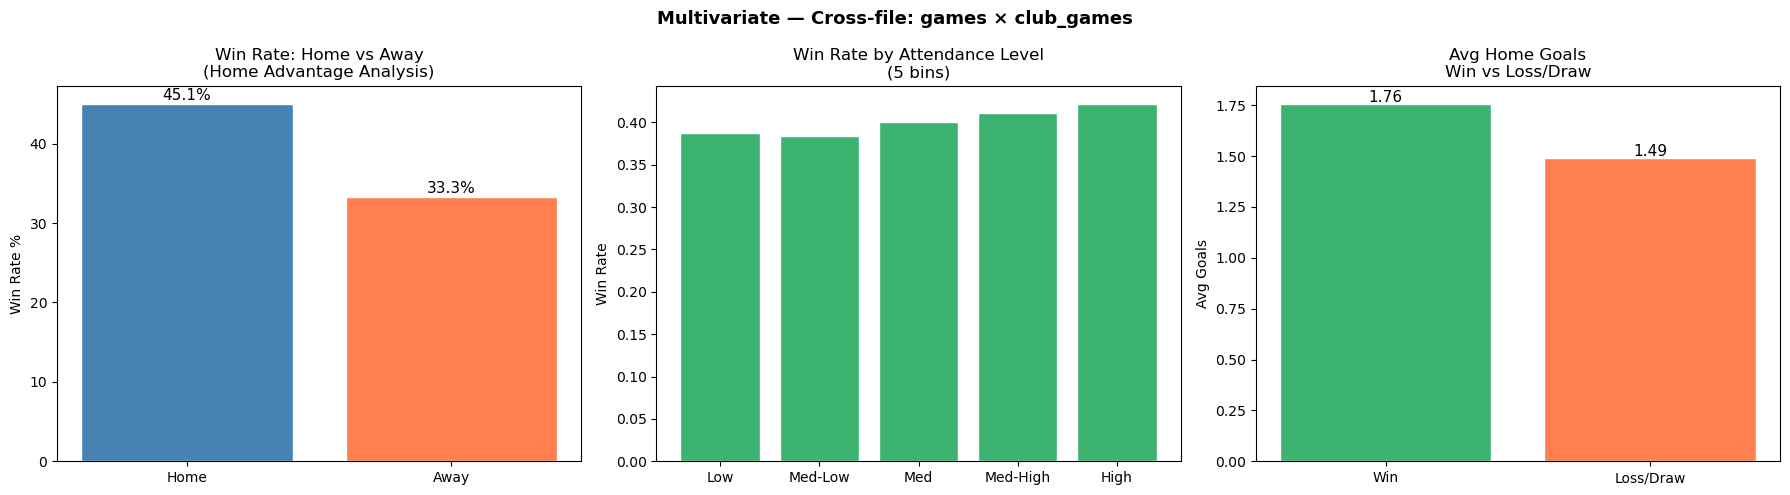

Saved


In [23]:
# Multivariate: Cross-file games × club_games

# Merge games + club_games
games_merged = games.merge(
    club_games[['game_id', 'club_id', 'is_win', 'hosting']],
    on='game_id', how='inner'
)
print(f"games × club_games merged: {games_merged.shape}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Home advantage: win rate home vs away
home_winrate = games_merged[games_merged['hosting'] == 'Home']['is_win'].mean()
away_winrate = games_merged[games_merged['hosting'] == 'Away']['is_win'].mean()

axes[0].bar(['Home', 'Away'],
            [home_winrate * 100, away_winrate * 100],
            color=['steelblue', 'coral'], edgecolor='white')
axes[0].set_title('Win Rate: Home vs Away\n(Home Advantage Analysis)')
axes[0].set_ylabel('Win Rate %')
for i, v in enumerate([home_winrate * 100, away_winrate * 100]):
    axes[0].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=11)

# Attendance vs win rate
att_bins = pd.cut(games_merged['attendance'], bins=5)
win_by_att = games_merged.groupby(att_bins, observed=True)['is_win'].mean()
axes[1].bar(range(len(win_by_att)), win_by_att.values,
            color='mediumseagreen', edgecolor='white')
axes[1].set_title('Win Rate by Attendance Level\n(5 bins)')
axes[1].set_ylabel('Win Rate')
axes[1].set_xticks(range(len(win_by_att)))
axes[1].set_xticklabels(['Low', 'Med-Low', 'Med',
                          'Med-High', 'High'], rotation=0)

# Goals vs win
goals_win  = games_merged[games_merged['is_win'] == 1]['home_club_goals'].mean()
goals_loss = games_merged[games_merged['is_win'] == 0]['home_club_goals'].mean()
axes[2].bar(['Win', 'Loss/Draw'], [goals_win, goals_loss],
            color=['mediumseagreen', 'coral'], edgecolor='white')
axes[2].set_title('Avg Home Goals\nWin vs Loss/Draw')
axes[2].set_ylabel('Avg Goals')
for i, v in enumerate([goals_win, goals_loss]):
    axes[2].text(i, v + 0.01, f'{v:.2f}', ha='center', fontsize=11)

plt.suptitle('Multivariate — Cross-file: games × club_games',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '10_games_vs_club_games_multivariate.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

In [24]:
# Reload all files
games        = pd.read_csv('../../data/raw/games.csv')
game_events  = pd.read_csv('../../data/raw/game_events.csv')
game_lineups = pd.read_csv('../../data/raw/game_lineups.csv', low_memory=False)
club_games   = pd.read_csv('../../data/raw/club_games.csv')

games['date']       = pd.to_datetime(games['date'])
game_events['date'] = pd.to_datetime(game_events['date'])

print("Reloaded!")
print(f"games columns: {games.columns.tolist()}")

Reloaded!
games columns: ['game_id', 'competition_id', 'season', 'round', 'date', 'home_club_id', 'away_club_id', 'home_club_goals', 'away_club_goals', 'home_club_position', 'away_club_position', 'home_club_manager_name', 'away_club_manager_name', 'stadium', 'attendance', 'referee', 'url', 'home_club_formation', 'away_club_formation', 'home_club_name', 'away_club_name', 'aggregate', 'competition_type']


Merged: (1269845, 13)
Columns: ['game_event_id', 'date', 'game_id', 'minute', 'type', 'club_id', 'club_name', 'player_id', 'description', 'player_in_id', 'player_assist_id', 'game_date', 'competition_id']


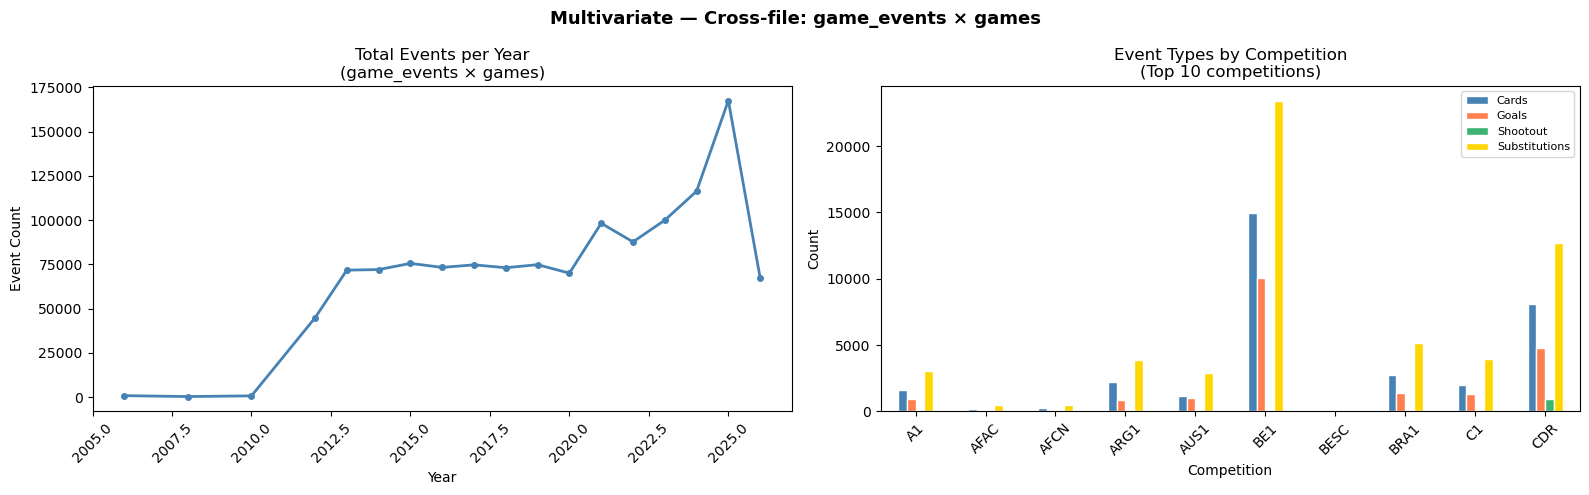

Saved


In [25]:
# Rename date trong games trước khi merge
games_subset = games[['game_id', 'date', 'competition_id']].copy()
games_subset = games_subset.rename(columns={'date': 'game_date'})

# Merge
events_merged = game_events.merge(games_subset, on='game_id', how='inner')

print(f"Merged: {events_merged.shape}")
print(f"Columns: {events_merged.columns.tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Events per year — dùng game_date thay vì date
events_trend = events_merged.groupby(
    pd.to_datetime(events_merged['game_date']).dt.year
)['type'].count()

axes[0].plot(events_trend.index, events_trend.values,
             color='steelblue', linewidth=2, marker='o', markersize=4)
axes[0].set_title('Total Events per Year\n(game_events × games)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Event Count')
axes[0].tick_params(axis='x', rotation=45)

# Event type by competition
top_events       = events_merged['type'].value_counts().head(5).index
event_comp       = events_merged[events_merged['type'].isin(top_events)]
event_comp_count = event_comp.groupby(
    ['competition_id', 'type']
).size().unstack(fill_value=0).head(10)

event_comp_count.plot(kind='bar', ax=axes[1],
                      color=['steelblue', 'coral',
                             'mediumseagreen', 'gold', 'purple'],
                      edgecolor='white')
axes[1].set_title('Event Types by Competition\n(Top 10 competitions)')
axes[1].set_xlabel('Competition')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=8)

plt.suptitle('Multivariate — Cross-file: game_events × games',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '11_game_events_vs_games_multivariate.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

Merged: (60465, 6)


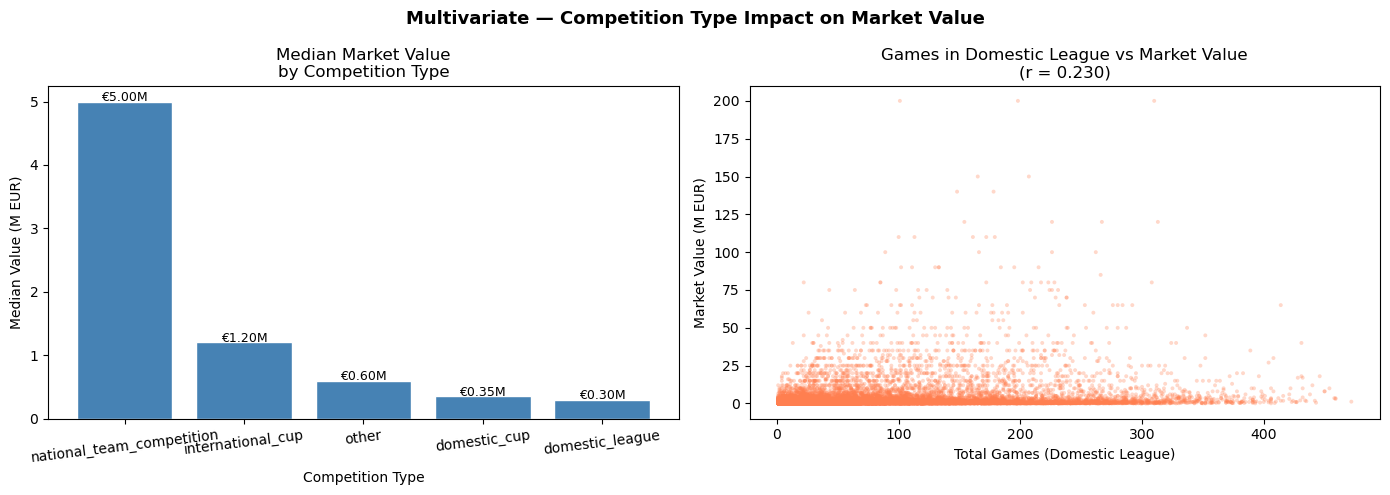

 Saved


In [26]:
appearances = pd.read_csv('../../data/raw/appearances.csv')
players     = pd.read_csv('../../data/raw/players.csv')

# Merge appearances + games để biết league
app_games = appearances.merge(
    games[['game_id', 'competition_id', 'competition_type']],
    on='game_id', how='inner'
)

# Aggregate by player + competition_type
player_comp = app_games.groupby(
    ['player_id', 'competition_type']
).agg(
    total_games   = ('game_id',        'count'),
    total_minutes = ('minutes_played', 'sum'),
    total_goals   = ('goals',          'sum')
).reset_index()

# Merge với market value
player_comp = player_comp.merge(
    players[['player_id', 'market_value_in_eur']],
    on='player_id', how='inner'
).dropna(subset=['market_value_in_eur'])

print(f"Merged: {player_comp.shape}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Median market value by competition type
comp_value = player_comp.groupby('competition_type')['market_value_in_eur']\
                         .median().sort_values(ascending=False)
axes[0].bar(comp_value.index, comp_value.values / 1_000_000,
            color='steelblue', edgecolor='white')
axes[0].set_title('Median Market Value\nby Competition Type')
axes[0].set_xlabel('Competition Type')
axes[0].set_ylabel('Median Value (M EUR)')
axes[0].tick_params(axis='x', rotation=7)
for i, v in enumerate(comp_value.values / 1_000_000):
    axes[0].text(i, v + 0.01, f'€{v:.2f}M', ha='center', fontsize=9)

# Total games in domestic league vs market value
domestic = player_comp[
    player_comp['competition_type'] == 'domestic_league'
]
corr = domestic['total_games'].corr(domestic['market_value_in_eur'])
axes[1].scatter(domestic['total_games'],
                domestic['market_value_in_eur'] / 1_000_000,
                alpha=0.3, color='coral', edgecolors='none', s=8)
axes[1].set_title(f'Games in Domestic League vs Market Value\n(r = {corr:.3f})')
axes[1].set_xlabel('Total Games (Domestic League)')
axes[1].set_ylabel('Market Value (M EUR)')

plt.suptitle('Multivariate — Competition Type Impact on Market Value',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '12_competition_type_vs_market_value.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Saved")

In [27]:
print("=== game_id Overlap Verification ===\n")

game_ids    = set(games['game_id'].unique())
event_ids   = set(game_events['game_id'].unique())
lineup_ids  = set(game_lineups['game_id'].unique())
clubg_ids   = set(club_games['game_id'].unique())

print(f"games.csv        : {len(game_ids):>8,} unique games")
print(f"game_events.csv  : {len(event_ids):>8,} unique games")
print(f"game_lineups.csv : {len(lineup_ids):>8,} unique games")
print(f"club_games.csv   : {len(clubg_ids):>8,} unique games")

print(f"\ngames ∩ events   : {len(game_ids & event_ids):>8,}")
print(f"games ∩ lineups  : {len(game_ids & lineup_ids):>8,}")
print(f"games ∩ clubs    : {len(game_ids & clubg_ids):>8,}")
print(f"\nAll 4 files ∩    : {len(game_ids & event_ids & lineup_ids & clubg_ids):>8,}")

=== game_id Overlap Verification ===

games.csv        :   88,665 unique games
game_events.csv  :   88,521 unique games
game_lineups.csv :   80,912 unique games
club_games.csv   :   88,665 unique games

games ∩ events   :   88,521
games ∩ lineups  :   80,912
games ∩ clubs    :   88,665

All 4 files ∩    :   80,902


In [28]:
# Multivariate: Relationships between files 

# Verify game_id overlap between files
app_games  = set(games['game_id'].unique())
event_games = set(game_events['game_id'].unique())
lineup_games = set(game_lineups['game_id'].unique())
club_g     = set(club_games['game_id'].unique())

print("=== game_id Overlap Verification ===")
print(f"games.csv        : {len(app_games):>7,} unique games")
print(f"game_events.csv  : {len(event_games):>7,} unique games")
print(f"game_lineups.csv : {len(lineup_games):>7,} unique games")
print(f"club_games.csv   : {len(club_g):>7,} unique games")
print(f"\ngames ∩ events  : {len(app_games & event_games):>7,}")
print(f"games ∩ lineups : {len(app_games & lineup_games):>7,}")
print(f"games ∩ clubs   : {len(app_games & club_g):>7,}")

=== game_id Overlap Verification ===
games.csv        :  88,665 unique games
game_events.csv  :  88,521 unique games
game_lineups.csv :  80,912 unique games
club_games.csv   :  88,665 unique games

games ∩ events  :  88,521
games ∩ lineups :  80,912
games ∩ clubs   :  88,665
